## 1. Import Libraries

In [1]:
# Import standard data science libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a folder to save our charts if it does not already exist
os.makedirs('figures', exist_ok=True)
print("Libraries imported and 'figures/' directory ready.")

Libraries imported and 'figures/' directory ready.


## 2. Load the Raw Dataset

In [2]:
# Load the raw dataset
df = pd.read_csv('Dataset/forest fires.csv')

# Preview the first 5 rows
df.head()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


## 3. Basic Dataset Inspection


In [ ]:
# Check the number of rows and columns
print("Dataset Shape (rows, columns):", df.shape)

Dataset Shape (rows, columns): (517, 13)


In [4]:
# Check column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB


In [5]:
# Summary statistics for numerical columns
df.describe()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


In [6]:
# Check for missing values in each column
df.isnull().sum()

X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

In [7]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 4


## 4. Remove Duplicate Rows

In [8]:
# Drop exact duplicate rows and reset the index
df = df.drop_duplicates().reset_index(drop=True)

# Verify the new shape and confirm no duplicates remain
print("New dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

New dataset shape: (513, 13)
Remaining duplicates: 0


## 5. Target Variable Analysis (`area`)

In [9]:
# Check target statistics and skewness
print("Minimum area:", df['area'].min())
print("Median area:", df['area'].median())
print("Mean area:", df['area'].mean())
print("Maximum area:", df['area'].max())
print("Target skewness:", df['area'].skew())

Minimum area: 0.0
Median area: 0.54
Mean area: 12.891598440545808
Maximum area: 1090.84
Target skewness: 12.802213419146321


In [10]:
# Count zero vs positive burned-area records
zero_count = (df['area'] == 0).sum()
positive_count = (df['area'] > 0).sum()

print(f"Zero area records: {zero_count} ({zero_count / len(df) * 100:.2f}%)")
print(f"Positive area records: {positive_count} ({positive_count / len(df) * 100:.2f}%)")

Zero area records: 244 (47.56%)
Positive area records: 269 (52.44%)


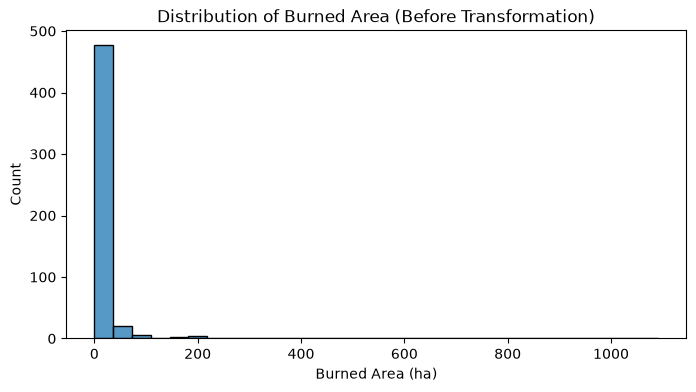

In [11]:
# Histogram of original area
plt.figure(figsize=(8, 4))
sns.histplot(df['area'], bins=30)
plt.title('Distribution of Burned Area (Before Transformation)')
plt.xlabel('Burned Area (ha)')
plt.ylabel('Count')
plt.savefig('figures/area_distribution_before_log.png', bbox_inches='tight')
plt.show()

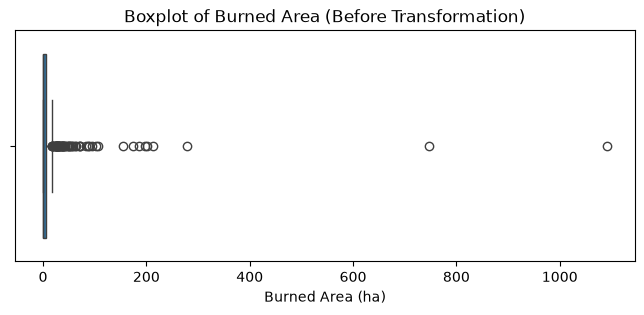

In [12]:
# Boxplot of original area
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['area'])
plt.title('Boxplot of Burned Area (Before Transformation)')
plt.xlabel('Burned Area (ha)')
plt.savefig('figures/area_boxplot_before_log.png', bbox_inches='tight')
plt.show()

## 6. Target Transformation (`log1p`)

In [13]:
# Create the log-transformed target column
df['area_log1p'] = np.log1p(df['area'])

# Check skewness after transformation
print("Original skewness:", df['area'].skew())
print("Transformed skewness:", df['area_log1p'].skew())

# Compare original area and log area side-by-side
df[['area', 'area_log1p']].head(10)

Original skewness: 12.802213419146321
Transformed skewness: 1.2193979428475714


,area,area_log1p
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0
5,0.0,0.0
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


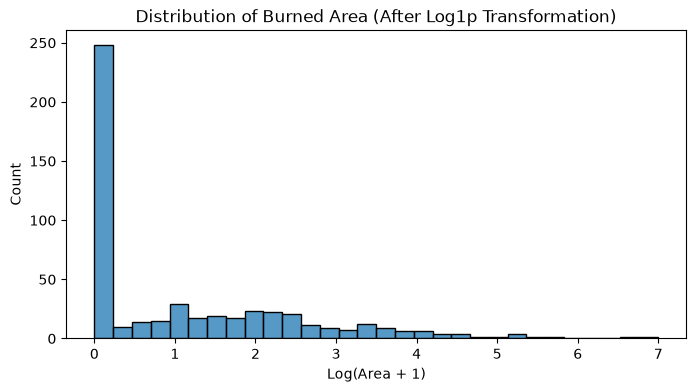

In [14]:
# Histogram of log-transformed area
plt.figure(figsize=(8, 4))
sns.histplot(df['area_log1p'], bins=30)
plt.title('Distribution of Burned Area (After Log1p Transformation)')
plt.xlabel('Log(Area + 1)')
plt.ylabel('Count')
plt.savefig('figures/area_distribution_after_log.png', bbox_inches='tight')
plt.show()

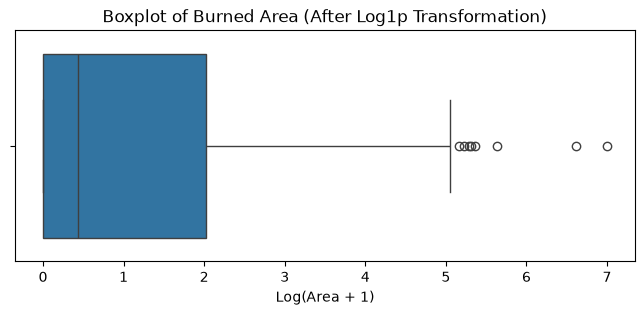

In [15]:
# Boxplot of log-transformed area
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['area_log1p'])
plt.title('Boxplot of Burned Area (After Log1p Transformation)')
plt.xlabel('Log(Area + 1)')
plt.savefig('figures/area_boxplot_after_log.png', bbox_inches='tight')
plt.show()

## 7. Comparing Zero vs Positive Burned Areas

In [16]:
# Helper column for EDA
df['area_status'] = np.where(df['area'] == 0, 'Zero area', 'Positive area')

# Compare median values between the two groups
weather_features = ['temp', 'RH', 'wind', 'rain', 'FFMC', 'DMC', 'DC', 'ISI']
df.groupby('area_status')[weather_features].median()

,temp,RH,wind,rain,FFMC,DMC,DC,ISI
area_status,,,,,,,,
Positive area,20.10,41.0,4.0,0.0,91.7,111.70,665.6,8.4
Zero area,18.55,42.0,3.6,0.0,91.6,102.75,661.3,8.4


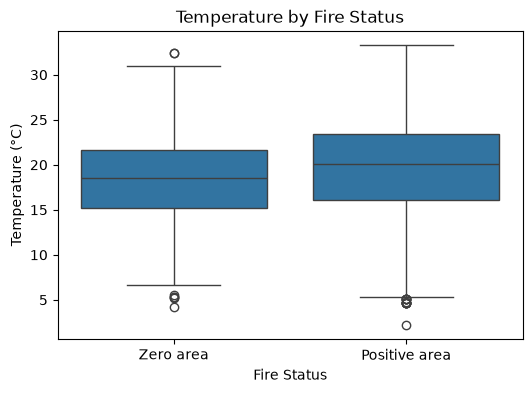

In [17]:
# Temperature comparison
plt.figure(figsize=(6, 4))
sns.boxplot(x='area_status', y='temp', data=df)
plt.title('Temperature by Fire Status')
plt.xlabel('Fire Status')
plt.ylabel('Temperature (°C)')
plt.savefig('figures/temp_by_area_status.png', bbox_inches='tight')
plt.show()

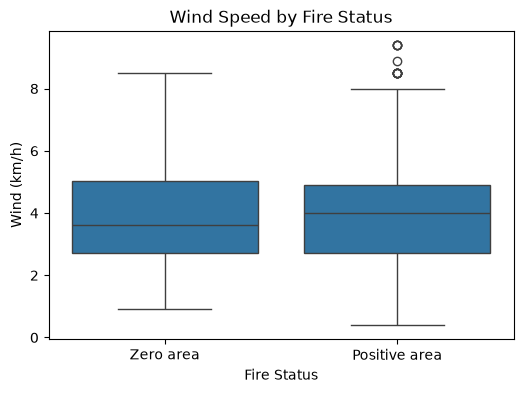

In [18]:
# Wind speed comparison
plt.figure(figsize=(6, 4))
sns.boxplot(x='area_status', y='wind', data=df)
plt.title('Wind Speed by Fire Status')
plt.xlabel('Fire Status')
plt.ylabel('Wind (km/h)')
plt.savefig('figures/wind_by_area_status.png', bbox_inches='tight')
plt.show()

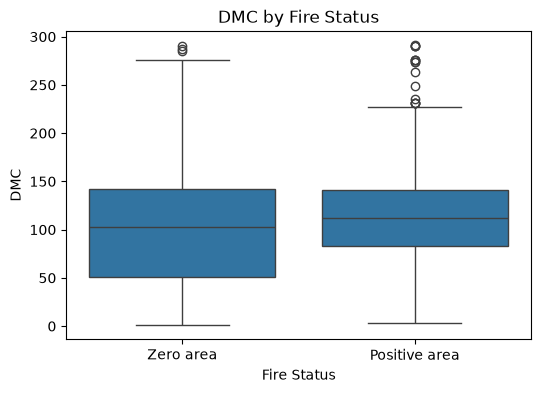

In [19]:
# DMC comparison
plt.figure(figsize=(6, 4))
sns.boxplot(x='area_status', y='DMC', data=df)
plt.title('DMC by Fire Status')
plt.xlabel('Fire Status')
plt.ylabel('DMC')
plt.savefig('figures/dmc_by_area_status.png', bbox_inches='tight')
plt.show()

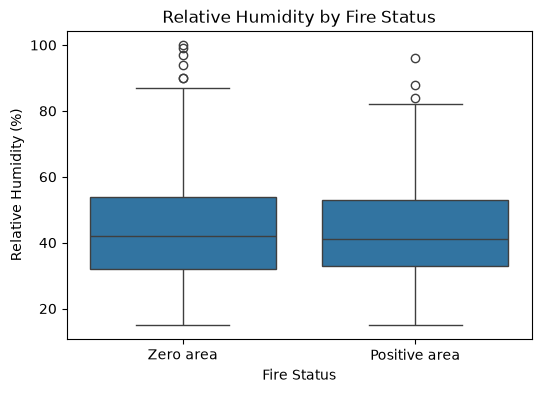

In [20]:
# Relative Humidity comparison
plt.figure(figsize=(6, 4))
sns.boxplot(x='area_status', y='RH', data=df)
plt.title('Relative Humidity by Fire Status')
plt.xlabel('Fire Status')
plt.ylabel('Relative Humidity (%)')
plt.savefig('figures/rh_by_area_status.png', bbox_inches='tight')
plt.show()

## 8. Fire Severity Groups (EDA)

In [21]:
# Calculate quartile cutoffs for positive fires
positive_areas = df[df['area'] > 0]['area']
q1 = positive_areas.quantile(0.25)
q2 = positive_areas.quantile(0.50)
q3 = positive_areas.quantile(0.75)

print(f"Quartiles: Q1={q1:.2f}, Q2={q2:.2f}, Q3={q3:.2f}")

# Assign descriptive groups
conditions = [
    df['area'] == 0,
    (df['area'] > 0) & (df['area'] <= q1),
    (df['area'] > q1) & (df['area'] <= q2),
    (df['area'] > q2) & (df['area'] <= q3),
    df['area'] > q3
]
group_labels = ['Zero area', 'Low positive', 'Moderate positive', 'High positive', 'Very high positive']
df['area_group'] = np.select(conditions, group_labels, default='Unclassified')

df['area_group'].value_counts()[group_labels]

Quartiles: Q1=2.14, Q2=6.36, Q3=15.34


area_group
Zero area             244
Low positive           69
Moderate positive      66
High positive          67
Very high positive     67
Name: count, dtype: int64

## 9. Monthly and Day-of-Week Patterns

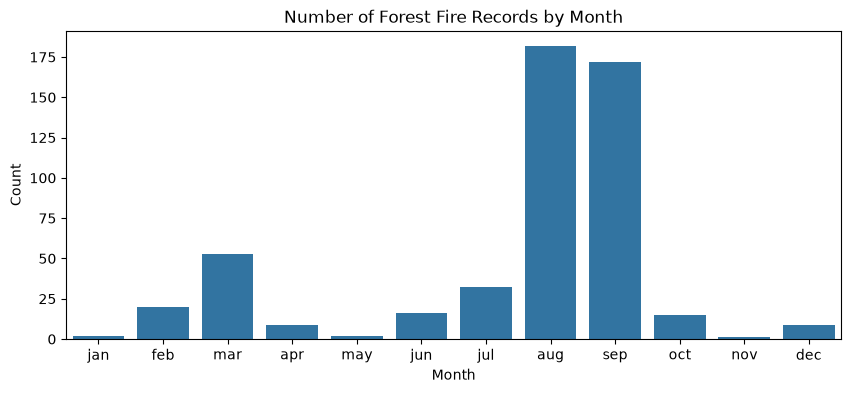

In [22]:
# Fire counts by month
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

plt.figure(figsize=(10, 4))
sns.countplot(x='month', data=df, order=month_order)
plt.title('Number of Forest Fire Records by Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.savefig('figures/monthly_fire_record_count.png', bbox_inches='tight')
plt.show()

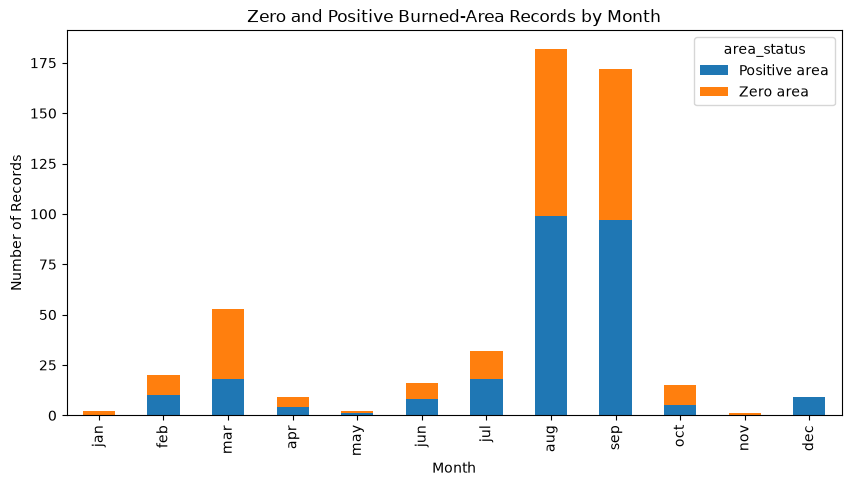

In [23]:
# Stacked bar chart: Zero vs Positive fires by month
monthly_status = pd.crosstab(df['month'], df['area_status']).reindex(month_order).fillna(0)

monthly_status.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Zero and Positive Burned-Area Records by Month')
plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.savefig('figures/monthly_zero_positive_counts.png', bbox_inches='tight')
plt.show()

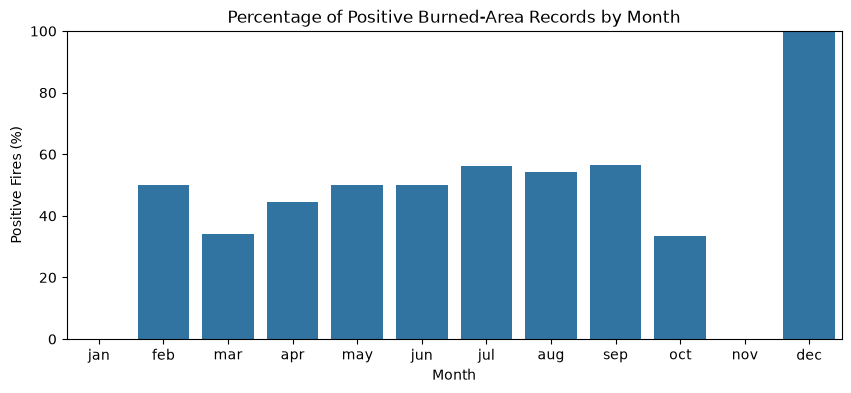

In [24]:
# Positive fire percentage by month
monthly_summary = df.groupby('month').agg(
    total=('area', 'count'),
    positive=('area', lambda x: (x > 0).sum())
).reindex(month_order)
monthly_summary['positive_pct'] = (monthly_summary['positive'] / monthly_summary['total'] * 100).fillna(0)

plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_summary.index, y=monthly_summary['positive_pct'], order=month_order)
plt.title('Percentage of Positive Burned-Area Records by Month')
plt.xlabel('Month')
plt.ylabel('Positive Fires (%)')
plt.ylim(0, 100)
plt.savefig('figures/monthly_positive_area_percentage.png', bbox_inches='tight')
plt.show()

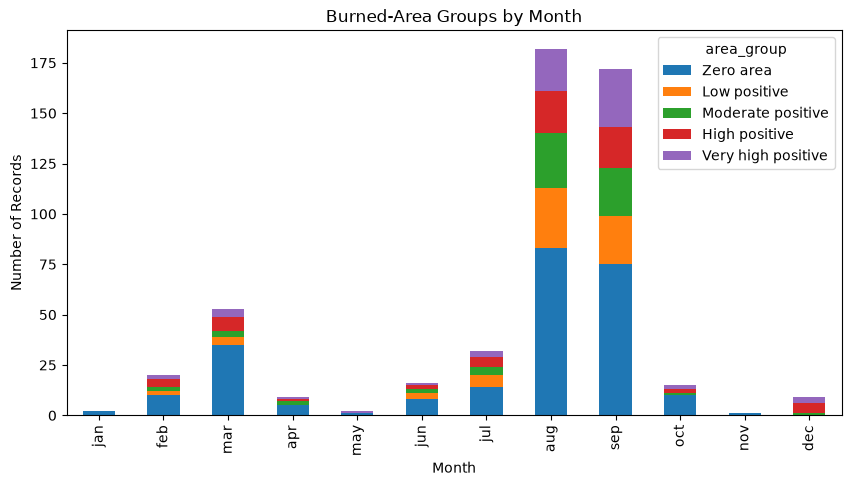

In [25]:
# Burned area groups count by month
monthly_groups = pd.crosstab(df['month'], df['area_group']).reindex(index=month_order, columns=group_labels).fillna(0)

monthly_groups.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Burned-Area Groups by Month')
plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.savefig('figures/burned_area_groups_by_month.png', bbox_inches='tight')
plt.show()

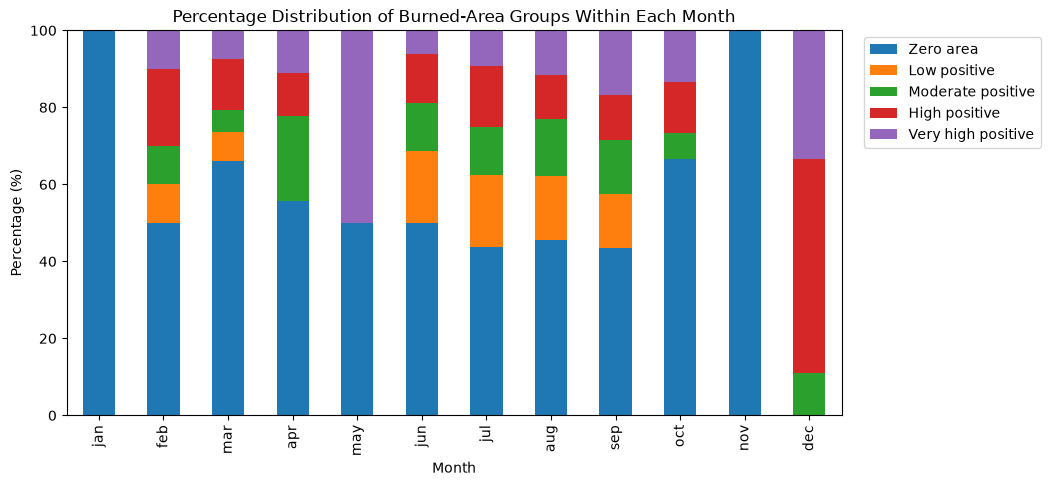

In [26]:
# Burned area groups 100% percentage within each month
monthly_group_pct = monthly_groups.div(monthly_groups.sum(axis=1), axis=0) * 100

monthly_group_pct.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Percentage Distribution of Burned-Area Groups Within Each Month')
plt.xlabel('Month')
plt.ylabel('Percentage (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig('figures/burned_area_group_percentage_by_month.png', bbox_inches='tight')
plt.show()

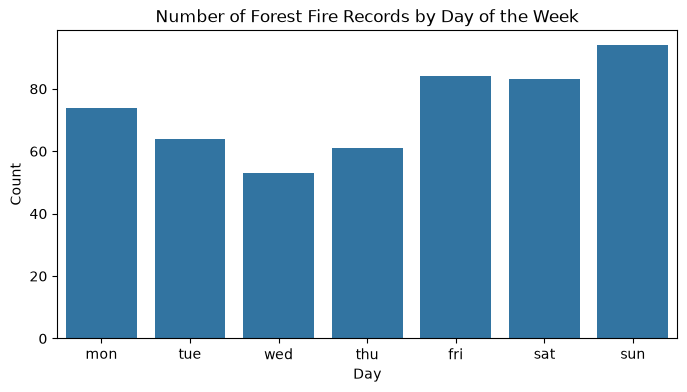

In [27]:
# Fire counts by day of week
day_order = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

plt.figure(figsize=(8, 4))
sns.countplot(x='day', data=df, order=day_order)
plt.title('Number of Forest Fire Records by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Count')
plt.savefig('figures/weekday_fire_record_count.png', bbox_inches='tight')
plt.show()

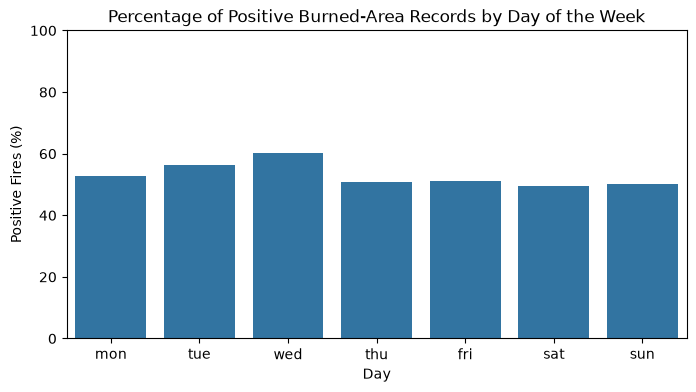

In [28]:
# Positive fire percentage by day of week
weekday_summary = df.groupby('day').agg(
    total=('area', 'count'),
    positive=('area', lambda x: (x > 0).sum())
).reindex(day_order)
weekday_summary['positive_pct'] = (weekday_summary['positive'] / weekday_summary['total'] * 100).fillna(0)

plt.figure(figsize=(8, 4))
sns.barplot(x=weekday_summary.index, y=weekday_summary['positive_pct'], order=day_order)
plt.title('Percentage of Positive Burned-Area Records by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Positive Fires (%)')
plt.ylim(0, 100)
plt.savefig('figures/weekday_positive_area_percentage.png', bbox_inches='tight')
plt.show()

## 10. Numerical Correlation Analysis

In [29]:
# Check correlation of all numerical columns with area and area_log1p
num_cols = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area', 'area_log1p']
corr_matrix = df[num_cols].corr()

print("Correlations with area_log1p:")
print(corr_matrix['area_log1p'].sort_values(ascending=False))

Correlations with area_log1p:
area_log1p    1.000000
area          0.524829
DC            0.072025
DMC           0.071648
wind          0.068162
X             0.060574
temp          0.055495
FFMC          0.047155
Y             0.040032
rain          0.023307
ISI          -0.009467
RH           -0.051930
Name: area_log1p, dtype: float64


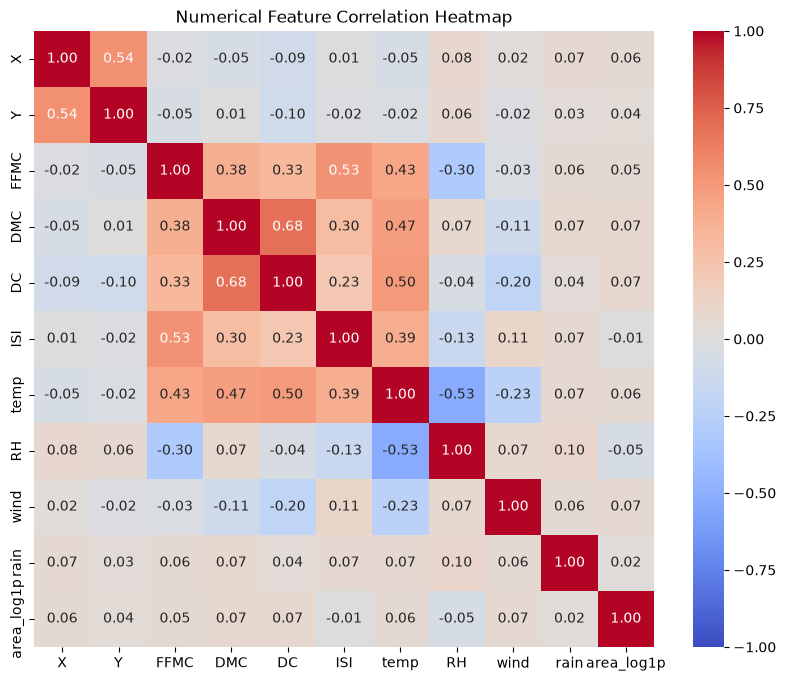

In [30]:
# Correlation heatmap
heatmap_cols = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain', 'area_log1p']

plt.figure(figsize=(10, 8))
sns.heatmap(df[heatmap_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numerical Feature Correlation Heatmap')
plt.savefig('figures/numerical_correlation_heatmap.png', bbox_inches='tight')
plt.show()

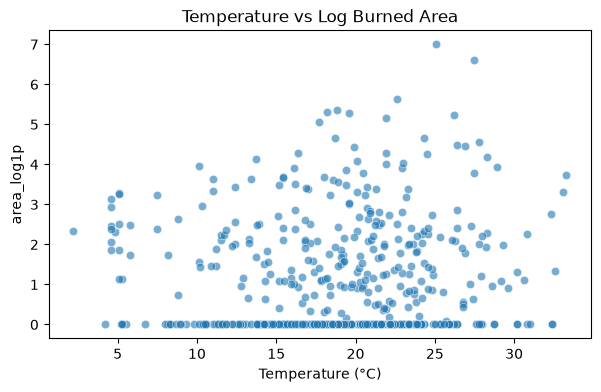

In [31]:
# Scatter plot: Temperature vs Log-Transformed Area
plt.figure(figsize=(7, 4))
sns.scatterplot(x='temp', y='area_log1p', data=df, alpha=0.6)
plt.title('Temperature vs Log Burned Area')
plt.xlabel('Temperature (°C)')
plt.ylabel('area_log1p')
plt.savefig('figures/temperature_vs_log_area.png', bbox_inches='tight')
plt.show()

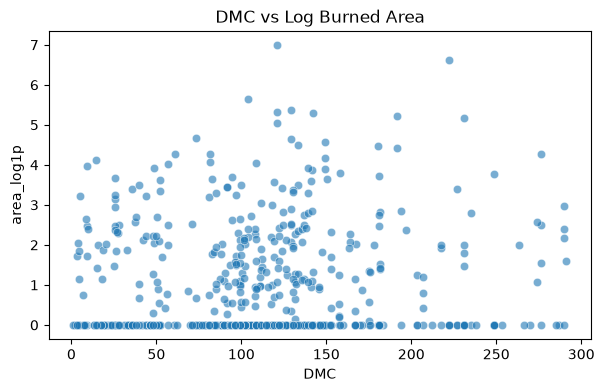

In [32]:
# Scatter plot: DMC vs Log-Transformed Area
plt.figure(figsize=(7, 4))
sns.scatterplot(x='DMC', y='area_log1p', data=df, alpha=0.6)
plt.title('DMC vs Log Burned Area')
plt.xlabel('DMC')
plt.ylabel('area_log1p')
plt.savefig('figures/dmc_vs_log_area.png', bbox_inches='tight')
plt.show()

## 11. Outlier Inspection (IQR Method)

In [33]:
# Check outliers in weather and index features
features_to_check = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

outlier_summary = []
for col in features_to_check:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        'Feature': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Outlier Count': count,
        'Outlier Pct': f"{count / len(df) * 100:.2f}%"
    })

pd.DataFrame(outlier_summary)

,Feature,Q1,Q3,IQR,Outlier Count,Outlier Pct
0,FFMC,90.2,92.9,2.7,53,10.33%
1,DMC,68.6,142.4,73.8,17,3.31%
2,DC,440.9,713.9,273.0,17,3.31%
3,ISI,6.4,11.0,4.6,14,2.73%
4,temp,15.5,22.8,7.3,2,0.39%
5,RH,33.0,53.0,20.0,12,2.34%
6,wind,2.7,4.9,2.2,13,2.53%
7,rain,0.0,0.0,0.0,8,1.56%


## 12. Spatial Feature Review (`X` and `Y`)

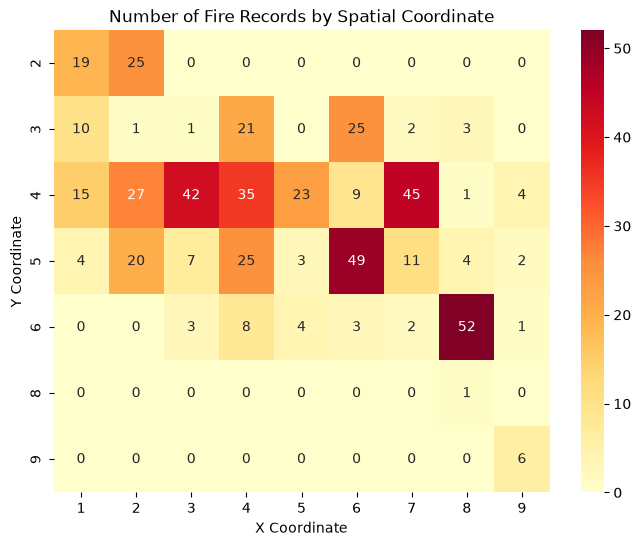

In [34]:
# Heatmap of fire record counts across X and Y grid coordinates
spatial_counts = pd.crosstab(df['Y'], df['X'])

plt.figure(figsize=(8, 6))
sns.heatmap(spatial_counts, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Number of Fire Records by Spatial Coordinate')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.savefig('figures/spatial_fire_record_heatmap.png', bbox_inches='tight')
plt.show()

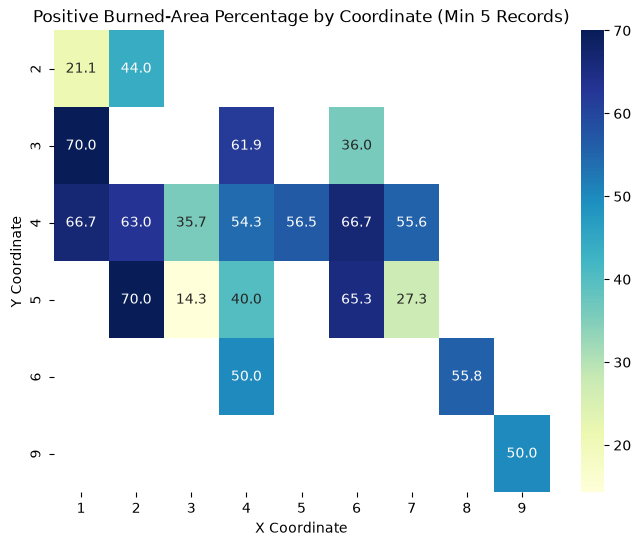

In [35]:
# Positive fire percentage by coordinate (for locations with at least 5 records)
spatial_stats = df.groupby(['Y', 'X']).agg(
    total=('area', 'count'),
    positive=('area', lambda x: (x > 0).sum())
).reset_index()

spatial_stats['positive_pct'] = spatial_stats['positive'] / spatial_stats['total'] * 100
filtered_spatial = spatial_stats[spatial_stats['total'] >= 5]

spatial_pivot = filtered_spatial.pivot(index='Y', columns='X', values='positive_pct')

plt.figure(figsize=(8, 6))
sns.heatmap(spatial_pivot, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Positive Burned-Area Percentage by Coordinate (Min 5 Records)')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.savefig('figures/spatial_positive_area_percentage.png', bbox_inches='tight')
plt.show()

## 13. Save the Cleaned Dataset

In [36]:
# Select the columns needed for modeling
columns_to_save = [
    'X', 'Y',
    'month', 'day',
    'FFMC', 'DMC', 'DC', 'ISI',
    'temp', 'RH', 'wind', 'rain',
    'area', 'area_log1p'
]

cleaned_df = df[columns_to_save].copy()

# Save cleaned dataset locally
cleaned_df.to_csv('Dataset/cleaned_forest_fires.csv', index=False)

print("Cleaned dataset successfully saved to 'Dataset/cleaned_forest_fires.csv'")
print("Cleaned shape:", cleaned_df.shape)
cleaned_df.head()

Cleaned dataset successfully saved to 'Dataset/cleaned_forest_fires.csv'
Cleaned shape: (513, 14)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area,area_log1p
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0,0.0
